# Fig 4: Behaviour and CA1 d2 in the cheeseboard task

This notebook reproduces the MATLAB figures 

| Panel | Content | 
|---|---|
| A | norm. path length per trial, acq1 trials 1-20 (violins; MATLAB: mean ± s.e.m. over trials 1-30) |
| B | the same for probe trials 1-5 | 
| C, D | CA1 d2 beginning vs end, start box / running | 
| E | CA1 d2 in the sleep box (awake rest) vs the maze beginning | 
| F, G | z.s. d2 vs z.s. norm. path length (z-scored within animal), start box / running | 
| H, I | GLM [FRm, FRstd, d2] drop-one ΔR² and normalised ΔR² (100 bootstraps) | 
| J, K | the same with [FRm, speed, d2] | 

Statistics follow MATLAB

In [8]:
import os, warnings
import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from scipy import stats, special

DATADIR = '../csv/Fig4_AK_behavior_d2'
FIGDIR = '../figure_output/Fig4'
os.makedirs(FIGDIR, exist_ok=True)

font_dir = 'fonts'
if os.path.exists(font_dir):
    for f in ['Regular', 'Bold']:
        fm.fontManager.addfont(f'{font_dir}/NimbusSans-{f}.ttf')

RC = {'font.family': 'sans-serif',
      'font.sans-serif': ['Helvetica', 'Nimbus Sans', 'Nimbus Sans TT', 'Arial'],
      'font.size': 7, 'axes.linewidth': 1,
      'xtick.major.width': 1, 'ytick.major.width': 1,
      'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
      'pdf.fonttype': 42,
      'axes.spines.top': False, 'axes.spines.right': False}

BLUE, GREY, BLACK, MUTED = '#2a78d6', '#b4b2a9', '#1f1f1d', '#8a887f'
ORANGE, GREEN, PURPLE = '#e67e22', '#27ae60', '#8c96c9'


In [9]:
# ---------- MATLAB-faithful statistics ----------
def bisquare(r):
    return (np.abs(r) < 1) * (1 - r ** 2) ** 2

def _madsigma(r, p):
    rs = np.sort(np.abs(r))
    return np.median(rs[max(1, p) - 1:]) / 0.6745

def robustfit(X, y, tune=4.685):
    # MATLAB statrobustfit + statrobustsigma; anova 'summary' as in LinearModel (robust SSE = DFE*s^2)
    X = np.column_stack([np.ones(len(y)), np.reshape(X, (len(y), -1))])
    n, p = X.shape
    Q, R = np.linalg.qr(X)
    b = np.linalg.solve(R, Q.T @ y)
    E = X @ np.linalg.inv(R)
    h = np.minimum(.9999, np.sum(E * E, 1)); adj = 1 / np.sqrt(1 - h)
    dfe = n - p
    ols_s = np.linalg.norm(y - X @ b) / np.sqrt(dfe)
    tiny = 1e-6 * np.std(y, ddof=1)
    D = np.sqrt(np.finfo(float).eps)
    b0 = np.zeros_like(b); it = 0
    while it == 0 or np.any(np.abs(b - b0) > D * np.maximum(np.abs(b), np.abs(b0))):
        it += 1
        if it > 50: break
        radj = (y - X @ b) * adj
        w = bisquare(radj / (max(_madsigma(radj, p), tiny) * tune))
        b0 = b; sw = np.sqrt(w)
        b = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]
    r = y - X @ b; radj = r * adj
    mad_s = _madsigma(radj, p)
    if np.all((w < D) | (w > 1 - D)):
        inc = w > 1 - D; robust_s = np.linalg.norm(r[inc]) / np.sqrt(inc.sum() - p)
    else:
        st = max(mad_s, tiny) * tune; u = radj / st; d = 1e-4
        phi = u * bisquare(u)
        dphi = ((u + d) * bisquare(u + d) - (u - d) * bisquare(u - d)) / (2 * d)
        m1 = dphi.mean(); m2 = np.sum((1 - h) * phi ** 2) / (n - p)
        robust_s = (1 + (p / n) * (1 - m1) / m1) * np.sqrt(m2) * st / m1
    sigma = max(robust_s, np.sqrt((ols_s ** 2 * p ** 2 + robust_s ** 2 * n) / (p ** 2 + n)))
    RI = np.linalg.inv(R); se = np.sqrt(np.diag(RI @ RI.T)) * sigma
    pv = 2 * stats.t.cdf(-np.abs(b / se), dfe)
    SSR = np.sum((X @ b - y.mean()) ** 2); SSE = dfe * sigma ** 2
    dfx = n - 1 - dfe
    pF = stats.f.sf((SSR / dfx) / (SSE / dfe), dfx, dfe)
    return dict(b=b, se=se, p=pv, R2=SSR / (SSR + SSE), pF=pF, cov=RI @ RI.T * sigma ** 2, dfe=dfe)

def signrank(d, tail='two-sided'):
    # MATLAB signrank: NaNs and zeros dropped; exact for n <= 15, else normal approximation without continuity correction
    d = np.asarray(d, float); d = d[~np.isnan(d)]; d = d[d != 0]
    return stats.wilcoxon(d, alternative=tail, method='exact' if len(d) <= 15 else 'approx', correction=False).pvalue

def spearman_matlab(x, y):
    ok = ~np.isnan(x) & ~np.isnan(y); x, y = np.asarray(x)[ok], np.asarray(y)[ok]; n = len(x)
    rho = np.corrcoef(stats.rankdata(x), stats.rankdata(y))[0, 1]
    if len(np.unique(x)) == n and len(np.unique(y)) == n and n >= 10:      # AS 89, as MATLAB corr
        n3 = (n ** 3 - n) / 3; stdD = n3 / (2 * np.sqrt(n - 1))
        Dv = n3 / 2 - round(rho * np.sqrt(n - 1) * stdD); Dv = max(Dv, n3 - Dv)
        c = [.2274, .2531, .1745, .0758, .1033, .3932, .0879, .0151, .0072, .0831, .0131, .00046]
        xx = (2 * (Dv - 1) / n3 - 1) * np.sqrt(n - 1); yy = xx * xx
        u = xx * (c[0] + (c[1] + c[2] / n) / n + yy * (-c[3] + (c[4] + c[5] / n) / n - yy * (c[6] + c[7] / n - yy * (c[8] - c[9] / n + yy * (c[10] - c[11] * yy) / n)) / n)) / n
        p = min(2 * min(max(u / np.exp(.5 * yy) + 0.5 * special.erfc(xx / np.sqrt(2)), 0), 1), 1)
    else:
        p = 2 * stats.t.cdf(-abs(rho * np.sqrt((n - 2) / (1 - rho ** 2))), n - 2)
    return rho, p, n

def q_hazen(v, qs):   # MATLAB quantile/prctile
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    return np.percentile(v, qs, method='hazen')

def pfmt(p):
    return f'{p:.2g}' if p >= 1e-3 else f'{p:.1e}'

def style_title(ax, txt, p, fs=5.6):
    sig = p < 0.05
    ax.set_title(txt + (' *' if sig else ''), fontsize=fs, pad=3,
                 fontweight='bold' if sig else 'normal', color=BLACK if sig else MUTED)

stat_rows = []
def add_stat(panel, test, stat, p, n, note=''):
    stat_rows.append(dict(panel=panel, test=test, stat=stat, p=p, n=n, note=note))

In [10]:
trials = pd.read_csv(f'{DATADIR}/fig4_trials_norm_path.csv')
sleep = pd.read_csv(f'{DATADIR}/fig4_sleep_vs_maze.csv')
sleep = sleep[sleep.region == 'CA1']
sc = pd.read_csv(f'{DATADIR}/fig4_d2_vs_path.csv')
be = pd.read_csv(f'{DATADIR}/fig4_d2_begin_end.csv')
glm = pd.read_csv(f'{DATADIR}/fig4_glm_sessions.csv')


def violins(ax, data, pos, color, w=0.75):
    parts = ax.violinplot(data, positions=pos, showextrema=False, widths=w)
    for pc in parts['bodies']:
        pc.set_facecolor(color); pc.set_alpha(0.3); pc.set_edgecolor('none')
    for v, x in zip(data, pos):
        q1, med, q3 = q_hazen(v, [25, 50, 75])
        ax.vlines(x, q1, q3, color=BLACK, lw=1)
        ax.scatter([x], [med], color=BLACK, s=5, zorder=5, lw=0)

def paired(ax, a, b, labels, color, ylabel):
    rng = np.random.default_rng(1)
    for v, x in [(a, 1), (b, 2)]:
        violins(ax, [v], [x], color, w=0.7)
        ax.scatter(x + rng.normal(0, 0.05, len(v)), v, s=3, color=color, alpha=0.6, lw=0, zorder=3)
    for u, v in zip(a, b):
        ax.plot([1, 2], [u, v], color=GREY, lw=0.3, alpha=0.7, zorder=1)
    ax.set_xticks([1, 2]); ax.set_xticklabels(labels); ax.set_ylabel(ylabel); ax.set_xlim(0.4, 2.6)

def mboxes(ax, D, labels, color):
    # similar to MATLAB daboxplot: IQR box, median line, whiskers to the most extreme point within 1.5 IQR, dashed line through medians
    meds = []
    for j in range(D.shape[1]):
        v = D[:, j]; v = v[~np.isnan(v)]
        q1, med, q3 = q_hazen(v, [25, 50, 75]); iqr = q3 - q1
        lo = v[v >= q1 - 1.5 * iqr].min(); hi = v[v <= q3 + 1.5 * iqr].max()
        x = j + 1; meds.append(med)
        ax.add_patch(plt.Rectangle((x - 0.17, q1), 0.34, q3 - q1, facecolor=color, edgecolor=BLACK, lw=0.6, alpha=0.85, zorder=2))
        ax.plot([x - 0.17, x + 0.17], [med, med], color=BLACK, lw=1.2, zorder=3)
        ax.plot([x, x], [lo, q1], color=BLACK, lw=0.6); ax.plot([x, x], [q3, hi], color=BLACK, lw=0.6)
        ax.plot([x - 0.08, x + 0.08], [lo, lo], color=BLACK, lw=0.6); ax.plot([x - 0.08, x + 0.08], [hi, hi], color=BLACK, lw=0.6)
    ax.plot(range(1, D.shape[1] + 1), meds, ls='--', color=color, lw=1, zorder=1)
    ax.axhline(0, color=GREY, lw=0.5, zorder=0)
    ax.set_xticks(range(1, D.shape[1] + 1)); ax.set_xticklabels(['w/o ' + l for l in labels], rotation=25, ha='right')
    ax.set_xlim(0.5, D.shape[1] + 0.5)

def letter(ax, s, x=-0.28, y=1.18):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom')

## A, B: norm. path length per trial

acq1 n = 49 KW p = 2.3e-65 significant trials: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
   mean of trials 1-5: [2.8142 1.8484 1.2894 1.3286 1.1001]
probe n = 44 KW p = 6.5e-14 significant trials: [np.int64(1), np.int64(2)]
   mean of trials 1-5: [1.676  0.9523 0.8218 0.7932 0.7878]


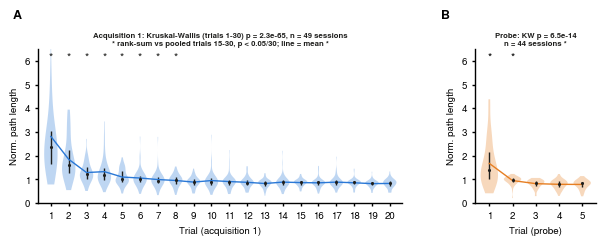

In [ ]:
# ---------- Panels A, B: norm. cumulative distance per trial ----------
# MATLAB: rows = all collected sessions of HP15/HP17/HP18; ranksum(trial k, pooled columns fix(end/2):end), Bonferroni 0.05/ntrials;
# kruskalwallis over the trial columns (rows with trial 1 present).
trial_stats = {}
for slot, panel, ntr in [('acq1', 'A', 30), ('probe', 'B', 5)]:
    piv = trials[trials.slot == slot].pivot_table(index='session', columns='trial', values='norm_path_length').reindex(columns=range(1, ntr + 1))
    late = piv.iloc[:, ntr // 2 - 1:].values.ravel(); late = late[~np.isnan(late)]
    pbon = 0.05 / ntr; sig = []
    for t in range(1, ntr + 1):
        v = piv[t].dropna().values
        p = stats.ranksums(v, late).pvalue
        sig.append(p < pbon)
        add_stat(panel, f'ranksum trial {t} vs pooled trials {ntr // 2}-{ntr}', np.nan, p, len(v), f'Bonferroni 0.05/{ntr}; sig={p < pbon}')
    H, pkw = stats.kruskal(*[piv[c].dropna().values for c in piv.columns])
    add_stat(panel, f'Kruskal-Wallis trials 1-{ntr}', H, pkw, len(piv))
    trial_stats[slot] = dict(piv=piv, sig=np.array(sig), pkw=pkw, n=len(piv))
    print(slot, 'n =', len(piv), 'KW p =', pfmt(pkw), 'significant trials:', list(np.where(sig)[0] + 1))
    print('   mean of trials 1-5:', np.round(piv.mean().values[:5], 4))

with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.0), gridspec_kw=dict(width_ratios=[3, 1], wspace=0.3))

    # A: acq1 trials 1-20
    ax = axs[0]; letter(ax, 'A', -0.07)
    st = trial_stats['acq1']; piv = st['piv']
    data = [piv[t].dropna().values for t in range(1, 21)]
    violins(ax, data, list(range(1, 21)), BLUE)
    m = piv.mean().values[:20]
    ax.plot(range(1, 21), m, color=BLUE, lw=1, zorder=4)
    for t in range(20):
        if st['sig'][t]:
            ax.text(t + 1, 6.15, '*', ha='center', va='center', fontsize=8, color=BLACK)
    ax.set_ylim(0, 6.5); ax.set_xlim(0.3, 20.7); ax.set_xticks(range(1, 21))
    ax.set_xlabel('Trial (acquisition 1)'); ax.set_ylabel('Norm. path length')
    style_title(ax, f"Acquisition 1: Kruskal-Wallis (trials 1-30) p = {pfmt(st['pkw'])}, n = {st['n']} sessions\n"
                f"* rank-sum vs pooled trials 15-30, p < 0.05/30; line = mean", st['pkw'])

    # B: probe
    ax = axs[1]; letter(ax, 'B')
    st = trial_stats['probe']; piv = st['piv']
    violins(ax, [piv[t].dropna().values for t in range(1, 6)], list(range(1, 6)), ORANGE)
    ax.plot(range(1, 6), piv.mean().values, color=ORANGE, lw=1, zorder=4)
    for t in range(5):
        if st['sig'][t]:
            ax.text(t + 1, 6.15, '*', ha='center', va='center', fontsize=8)
    ax.set_ylim(0, 6.5); ax.set_xticks(range(1, 6)); ax.set_xlabel('Trial (probe)'); ax.set_ylabel('Norm. path length')
    style_title(ax, f"Probe: KW p = {pfmt(st['pkw'])}\nn = {st['n']} sessions", st['pkw'])

    fig.savefig(f'{FIGDIR}/Fig4_AB.pdf', bbox_inches='tight')
    plt.show()

## C–E: d2 beginning vs end, and sleep box vs maze

start box n = 49 p = 1.204e-03
running n = 49 p = 2.202e-08


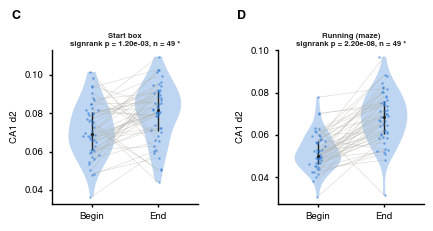

In [12]:
# ---------- Panels C, D: d2 beginning vs end (figure(5), d2start_box_maze.fig) ----------
with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 2, figsize=(4.8, 2.0), gridspec_kw=dict(wspace=0.55))
    for ax, (w, L) in zip(axs, [('start box', 'C'), ('running', 'D')]):
        d = be[be.window == w]
        p = signrank(d.d2_end - d.d2_begin)
        add_stat(L, f'signrank d2 begin vs end ({w})', np.nan, p, len(d),
                 f'median begin {d.d2_begin.median():.4f}, end {d.d2_end.median():.4f}')
        print(w, 'n =', len(d), 'p =', f'{p:.3e}')
        letter(ax, L)
        paired(ax, d.d2_begin.values, d.d2_end.values, ['Begin', 'End'], BLUE, 'CA1 d2')
        style_title(ax, f"{'Start box' if w == 'start box' else 'Running (maze)'}\nsignrank p = {p:.2e}, n = {len(d)}", p)

    fig.savefig(f'{FIGDIR}/Fig4_CD.pdf', bbox_inches='tight')
    plt.show()

CA1 n = 90 p = 0.00000 {'AYA7': 3, 'AYA9': 4, 'HP15': 27, 'HP18': 32, 'RM04': 6, 'RM10': 18}


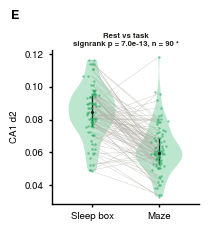

In [13]:
# ---------- Panel E: sleep box (awake rest) vs maze beginning (homecage pipeline) ----------
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.9, 2.0))
    p = signrank(sleep.d2_maze - sleep.d2_sleep)
    add_stat('E', 'signrank sleep box vs maze (CA1)', np.nan, p, len(sleep), f'{sleep.animal.nunique()} animals')
    print('CA1 n =', len(sleep), 'p =', f'{p:.5f}', sleep.groupby('animal').size().to_dict())
    letter(ax, 'E')
    paired(ax, sleep.d2_sleep.values, sleep.d2_maze.values, ['Sleep box', 'Maze'], GREEN, 'CA1 d2')
    style_title(ax, f"Rest vs task\nsignrank p = {pfmt(p)}, n = {len(sleep)}", p)

    fig.savefig(f'{FIGDIR}/Fig4_E.pdf', bbox_inches='tight')
    plt.show()

## F, G: d2 vs norm. path length

startbox R2 0.07 p 0.058 co -0.03 0.28 | rho 0.32 p 2.628e-02 n 49
running R2 0.17 p 0.004 co 0.01 0.43 | rho 0.39 p 5.897e-03 n 49


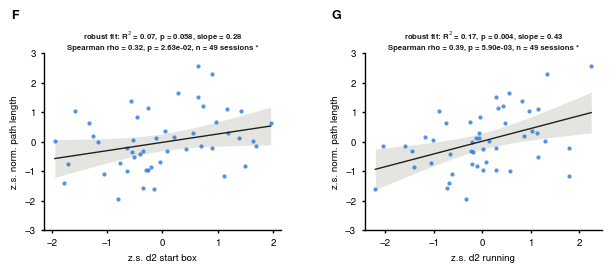

In [14]:
# ---------- Panels F, G: z.s. d2 vs z.s. norm. path length (robust fit + Spearman) ----------
with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.3), gridspec_kw=dict(wspace=0.35))
    for ax, (w, L, xl) in zip(axs, [('startbox', 'F', 'z.s. d2 start box'), ('running', 'G', 'z.s. d2 running')]):
        x = sc[f'z_d2_{w}'].values; y = sc.z_norm_path_length.values
        rf = robustfit(x, y)
        rho, prho, n = spearman_matlab(x, y)
        add_stat(L, f'robust fitlm z.s. path ~ z.s. d2 {w}', rf['R2'], rf['pF'], n,
                 f"R2={rf['R2']:.3f}; coef {rf['b'][0]:.4f}, {rf['b'][1]:.4f}; slope SE {rf['se'][1]:.4f} p {rf['p'][1]:.4f}")
        add_stat(L, f'Spearman z.s. d2 {w} vs z.s. path', rho, prho, n)
        print(w, f"R2 {rf['R2']:.2f} p {rf['pF']:.3f} co {rf['b'][0]:.2f} {rf['b'][1]:.2f} | rho {rho:.2f} p {prho:.3e} n {n}")

        letter(ax, L, -0.14)
        # points, robust fit line and its 95 % CI
        ax.scatter(x, y, s=9, color=BLUE, lw=0, alpha=0.8, zorder=3)
        xs = np.linspace(np.nanmin(x), np.nanmax(x), 50)
        Xs = np.column_stack([np.ones_like(xs), xs])
        yh = Xs @ rf['b']
        ci = stats.t.ppf(.975, rf['dfe']) * np.sqrt(np.einsum('ij,jk,ik->i', Xs, rf['cov'], Xs))
        ax.fill_between(xs, yh - ci, yh + ci, color=GREY, alpha=0.35, lw=0, zorder=1)
        ax.plot(xs, yh, color=BLACK, lw=1, zorder=4)
        ax.set_xlabel(xl); ax.set_ylabel('z.s. norm. path length')
        ax.set_ylim(-3, 3)
        style_title(ax, f"robust fit: R$^2$ = {rf['R2']:.2f}, p = {rf['pF']:.3f}, slope = {rf['b'][1]:.2f}\n"
                    f"Spearman rho = {rho:.2f}, p = {prho:.2e}, n = {n} sessions", min(rf['pF'], prho))

    fig.savefig(f'{FIGDIR}/Fig4_FG.pdf', bbox_inches='tight')
    plt.show()

## H–K: GLM drop-one ΔR²

B dR2 valid boots 100 medians [-0.0161  0.007   0.2866] p>0 ['1', '0.58', '9.5e-08'] pairwise ['0.0023', '3.1e-09', '8.5e-09']
B dR2norm valid boots 100 medians [-0.0791  0.0278  1.1328] p>0 ['1', '0.52', '1.3e-08'] pairwise ['0.0011', '3.7e-10', '1.5e-09']
A dR2 valid boots 100 medians [ 0.038  -0.0062  0.2855] p>0 ['0.0019', '1', '4.7e-08'] pairwise ['3.9e-04', '1.8e-06', '6.6e-09']
A dR2norm valid boots 100 medians [ 0.1583 -0.0265  1.1111] p>0 ['0.002', '1', '1.8e-08'] pairwise ['9.6e-04', '8.2e-07', '2.6e-09']


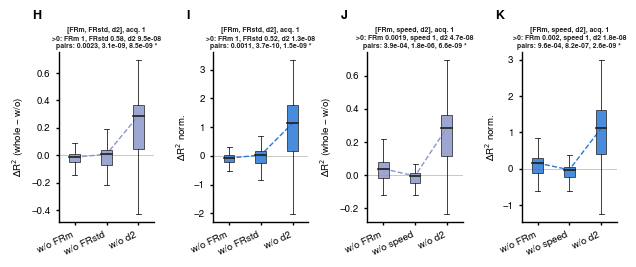

In [15]:
# ---------- Panels H-K: GLM with drop-one robust models ----------
NBOOT, NTEST, NSHUF, SEED = 100, 10, 20, 0
y_all = glm.z_norm_path_length.values

def _fit(X, y, robust):
    ok = ~np.isnan(X).any(1) & ~np.isnan(y)
    if robust:
        return robustfit(X[ok], y[ok])['b']
    A = np.column_stack([np.ones(ok.sum()), X[ok]])
    return np.linalg.lstsq(A, y[ok], rcond=None)[0]

def _r2(b, X, y):
    yp = b[0] + X @ b[1:]
    return 1 - np.sum((yp - y) ** 2) / np.sum(y ** 2)   # NaN propagates like MATLAB sum

def run_glm(cols, seed):
    X = glm[cols].values; y = y_all; n = len(y)
    rng = np.random.default_rng(seed)
    R2 = np.full((NBOOT, 2 + len(cols)), np.nan); R2sd = np.full(NBOOT, np.nan)
    for kb in range(NBOOT):
        c = rng.permutation(n); tr, te = c[:n - NTEST - 1], c[n - NTEST - 1:]
        R2[kb, 0] = _r2(_fit(X[tr], y[tr], False), X[te], y[te])
        sh = []
        for _ in range(NSHUF):
            py = y[rng.permutation(n)]
            sh.append(_r2(_fit(X[tr], py[tr], True), X[te], py[te]))
        R2[kb, 1] = np.mean(sh); R2sd[kb] = np.std(sh, ddof=1)
        for j in range(len(cols)):
            Xs = np.delete(X, j, 1)
            R2[kb, 2 + j] = _r2(_fit(Xs[tr], y[tr], True), Xs[te], y[te])
    dR2 = R2[:, [0]] - R2[:, 2:]
    norm = (R2 - R2[:, [1]]) / R2sd[:, None]
    dN = norm[:, [0]] - norm[:, 2:]
    return dR2, dN

def glm_tests(D):
    p1 = [signrank(D[:, k], 'greater') for k in range(D.shape[1])]
    p2 = [signrank(D[:, k] - D[:, 0]) for k in range(1, D.shape[1])] + [signrank(D[:, -2] - D[:, -1])]
    return p1, p2

SETS = {'B': (['z_FRm', 'z_FRstd', 'z_d2_begin_running'], ['FRm', 'FRstd', 'd2']),
        'A': (['z_FRm', 'z_speed', 'z_d2_begin_running'], ['FRm', 'speed', 'd2'])}
glm_res = {}
for s, (cols, labs) in SETS.items():
    dR2, dN = run_glm(cols, SEED)
    glm_res[s] = dict(dR2=dR2, dN=dN, labs=labs)
    for kind, D, panel in [('dR2', dR2, 'H' if s == 'B' else 'J'), ('dR2norm', dN, 'I' if s == 'B' else 'K')]:
        p1, p2 = glm_tests(D)
        glm_res[s][kind + '_p'] = (p1, p2)
        nval = int((~np.isnan(D[:, 0])).sum())
        for j, lab in enumerate(labs):
            q = q_hazen(D[:, j], [25, 50, 75])
            add_stat(panel, f'set {s} {kind} w/o {lab} > 0 (signrank right)', q[1], p1[j], nval,
                     f'median; IQR [{q[0]:.4f}, {q[2]:.4f}]; mean {np.nanmean(D[:, j]):.4f}; seed {SEED}')
        for nm, p in zip([f'{labs[1]} vs {labs[0]}', f'{labs[2]} vs {labs[0]}', f'{labs[1]} vs {labs[2]}'], p2):
            add_stat(panel, f'set {s} {kind} signrank {nm}', np.nan, p, nval, f'seed {SEED}')
        print(s, kind, 'valid boots', nval, 'medians', np.round(q_hazen(D, 50) if False else np.nanmedian(D, 0), 4),
              'p>0', [pfmt(p) for p in p1], 'pairwise', [pfmt(p) for p in p2])

with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.2), gridspec_kw=dict(wspace=0.62))
    for ax, (s, kind, L, yl) in zip(axs, [('B', 'dR2', 'H', 'ΔR$^2$ (whole − w/o)'), ('B', 'dR2norm', 'I', 'ΔR$^2$ norm.'),
                                          ('A', 'dR2', 'J', 'ΔR$^2$ (whole − w/o)'), ('A', 'dR2norm', 'K', 'ΔR$^2$ norm.')]):
        letter(ax, L)
        res = glm_res[s]; D = res['dR2' if kind == 'dR2' else 'dN']; labs = res['labs']
        mboxes(ax, D, labs, PURPLE if kind == 'dR2' else BLUE)
        p1, p2 = res[kind + '_p']
        ax.set_ylabel(yl)
        head = f"[FRm, {labs[1]}, d2], acq. 1"
        style_title(ax, f"{head}\n>0: {labs[0]} {pfmt(p1[0])}, {labs[1]} {pfmt(p1[1])}, d2 {pfmt(p1[2])}"
                    f"\npairs: {pfmt(p2[0])}, {pfmt(p2[1])}, {pfmt(p2[2])}", p1[2], fs=5)

    fig.savefig(f'{FIGDIR}/Fig4_HK.pdf', bbox_inches='tight')
    plt.show()